In [1]:
import sys, time, json, glob, os
from pathlib import Path
_t0 = time.time()
p = Path.cwd().resolve()
while not (p / 'C' / 'evoca.h').exists():
    if p.parent == p: raise FileNotFoundError('EvoCA repo root not found')
    p = p.parent
ROOT = p
sys.path.insert(0, str(ROOT / 'python'))
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from evoca_py import import_run
from evoca_explore import _spatial_metrics
WS = 'Reaction-diffusion'
RUNS = ROOT / 'Research' / WS / 'Runs'; SCANS = ROOT / 'Research' / WS / 'Scans'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)

# Reaction-diffusion: lab notebook

**Question.** What reaction-diffusion (RD) spatial regimes does EvoCA produce, which recipes (food_inc, tax, gdiff, m_scale, mu_lut, ...) produce them, and are they robust under evolution? RD is the one workstream with two real objectives (spatial structure vs. evolutionary activity), and it is also the gallery: the most photogenic EvoCA sims live here.

Links: digest [digests/RD-robustness.ipynb](digests/RD-robustness.ipynb) (campaign #4) · scans [2026-04-27_initial](Scans/2026-04-27_initial/notes.md), [refined](Scans/2026-04-27_refined/notes.md), [push_edges](Scans/2026-04-27_push_edges/notes.md), [cross-scan analysis](Scans/2026-04-27_scan_analysis.md), [2026-05-18_rd_under_pure_evo](Scans/2026-05-18_rd_under_pure_evo/notes.md). (The 2026-04-27 `evo_focus` scan is owned by Activity-metrics.)

Every simulation in this notebook is an **example run** at N=128 (one N=256 showcase), seed 0, at most 12000 steps, not a campaign result. The scans ran N=256, 5000 steps, halfplane start; N=128 grids fill in sooner, so numbers differ from `results.csv` and are compared side by side where they exist.

**Running the examples interactively.** After each example run there is a code cell of commented-out lines that open the same configuration in the interactive SDL window (`run_with_controls`, from `python/controls.py`). Uncomment and run it to watch the simulation; it is commented out so that *Run All* never blocks on a window. Only one EvoCA lattice exists at a time, so this replaces any simulation still alive in the kernel. Runs now use the capped mouthful (`food_cap=1`, the A9 fix); the outputs stored in this notebook were computed before it.

*Snapshot of `ISSUES.md` as of the last execution of this notebook; `ISSUES.md` is the source of truth.*

In [2]:
display(Markdown((ROOT/'Research'/WS/'ISSUES.md').read_text()))

# Reaction-diffusion: issues and directions
_Updated 2026-10-15_

## Decisions needed (N)
- **RXD-D1**: What is the second objective for RD selection? — Options: (a) evolutionary activity as before (`n_distinct_genomes_temporal_std` + `unique_top_genomes`, which saturates at the sample cap, see `Scans/2026-04-27_scan_analysis.md` obs. 8); (b) dyn_excess / A_new on eff_activity species (Activity-metrics, merged 2026-10-15); (c) lineage net-return (D2) or per-capita dissipation Phi (L1) as a more adaptive axis (`Docs/Oct2026/00-review-of-prompt1.md` §7). Recommendation: run RXD-N1 first with (a), then repeat with (b); defer (c). Blocks the final form of RXD-N1.
- **RXD-D2**: Is the halfplane start the RD protocol, or should RD be scored from a uniform random start (`init='fraction'`) and/or after a burn-in? — The halfplane start makes the first ~N steps an invasion front, so every 04-27 spatial metric partly measures that transient (observed in this notebook's N=128 runs, not a campaign result). Recommendation: keep halfplane for continuity but add a burn-in variant (RXD-N2). Blocks any re-run of the scans.
- **RXD-D3**: Keep the 85 recipes in `Runs/` as is, or dedupe? — About 55 distinct configs; `top_N`, `top_evo_N`, `auto_*` and three `best_corr_length` recipes repeat the same metaparameters under different ranking labels. Recommendation: keep (names record which ranking picked a config; disk cost trivial), add a note in the README only. Low urgency.

## Open questions
- **RXD-Q1**: Is the correlation-length plateau (~75-80, about N/3) a grid-size ceiling? — Recorded as a hypothesis in `Scans/2026-04-27_scan_analysis.md` (recommended step 2); never tested at N=384/512.
- **RXD-Q2**: Does the #4 decay verdict hold for the higher-scoring push_edges winners? — The campaign's ten bases are all `initial`-scan recipes (`top_N_cfg*_score0.55-0.75`); the push_edges and evo_focus winners (corr_len 60-80, the actual "best" spatial configs) were not in `Scans/2026-05-18_rd_under_pure_evo/scan.py::load_bases`'s output. Cheap to extend with the existing harness.
- **RXD-Q3**: Which of the visual regimes are attractors versus transients? — In this notebook's N=128 example runs the dot-lattice and salt-and-pepper states are end states, the invasion-front and sparse-colony regimes are transient; not established at N=256/long horizon. Needs a classification metric beyond correlation length (the labyrinth, cfg53, has corr_len ~1 yet clear texture).
- **RXD-Q4**: Is there a persistent regime at `gdiff` far above the scanned range? — `fill_dead_region_with_evolving_patches` uses gdiff=20 (frozen domain mosaic); every scan grid stops at gdiff 0.20. Unscanned.
- **RXD-Q5**: Does `waves_in_blank_half` ever give sustained waves? — Its saved *initial* metaparams go extinct by ~t=200 (N=128/256/512, seeds 0-1, example runs); with the saved *final* metaparams it is a one-shot invasion front, not a sustained wave. Two-parameter descriptor ambiguity in recipes (`metaparams_init` vs `metaparams_final`) is worth a note on any recipe promoted to a gallery.

## Next directions
- **RXD-N1**: Re-select the 04-27 winners with conepareto box and wedge and compare with the composite top-20 — analysis (no new dev; package exists at `~/Projects/conepareto`). Concrete first experiment: pool the candidates of `initial`/`refined`/`push_edges`; spatial score = mean of normalized `correlation_length_mean` and `largest_patch_temporal_std`, evolution score = mean of normalized `n_distinct_genomes_temporal_std` and `unique_top_genomes` (a preview with these choices is in the notebook, section "Two objectives"); form top-20 by (i) composite mean, (ii) box with 0.5/0.5 exclusion floors, (iii) wedge with `max_imbalance=0.15`; report overlap and Pareto layers; then run each distinct set (3 seeds, N=256, 12000 steps, the #4 harness) and score by persistence (`correlation_length_final/mean`, `largest_patch_final/mean`) plus final `dyn_excess_pc`: the selection method that keeps structure with turnover wins. Cross-ref: H1 (adaptive vs drift) for the evolution axis.
- **RXD-N2**: Burn-in / persistence-based spatial metrics — analysis, needs a small harness change (`python/evoca_explore.py` is outside this workstream; request via dev). Report spatial metrics after a burn-in (e.g. last half of the run) and final/mean as first-class scan columns.
- **RXD-N3**: Extend campaign #4 to the push_edges/evo_focus winners (RXD-Q2) and to N=384/512 (RXD-Q1) — campaign, existing harness, torque-scale compute (30 workers).
- **RXD-N4**: Scan gdiff in [0.2, 20] together with m_scale (RXD-Q4) — campaign.
- **RXD-N5**: Add a visual-regime classifier or texture metric (e.g., structure-factor peak, anisotropy) so regime names in the notebook gallery become measured labels — needs dev (analysis helper), cross-ref Criticality-bifurcation for order-parameter ideas.

## Parked
- Larger-N interactive visual validation of scan winners in the SDL viewer (recommended in the 04-27 analysis, step 1); superseded by the headless N=256 gallery in the notebook.
- Spirals/rotating waves: none observed in the gallery runs; do not pursue unless a scan turns one up.
- Fixing `evoca_set_seed` per task in pool workers is done (`build_sim` reseeds); the 04-27 note about shared RNG state predates it.


In [3]:
# ---- helpers -------------------------------------------------------------
def rgb(sim, N, cm):
    buf = np.zeros(N*N, np.int32); sim.colorize(buf, cm)
    a = buf.view(np.uint32).reshape(N, N)
    return np.stack([(a>>16)&255, (a>>8)&255, a&255], -1).astype(np.uint8)

def load(name, N, recipe='init', seed=0):
    global _SIM
    try: _SIM.free()
    except Exception: pass
    sim, kw = import_run(name, N=N, recipe=recipe); sim.set_seed(seed); _SIM = sim
    return sim

def run_track(name, N=128, snaps=(150, 600, 2000), n_steps=2000, every=25, recipe='init', seed=0, cms=(0, 1, 3)):
    """Run one recipe; return snapshots {t: {cm: rgb}} and a metrics time series."""
    sim = load(name, N, recipe, seed)
    ts, rows, shots = [], [], {}
    for t in range(1, n_steps + 1):
        sim.step()
        if t % every == 0:
            al = sim.get_alive().reshape(N, N).copy(); F = sim.get_F().reshape(N, N).copy()
            m = _spatial_metrics(al, F); ts.append(t); rows.append(m)
        if t in snaps:
            shots[t] = {cm: rgb(sim, N, cm) for cm in cms}
    df = pd.DataFrame(rows, index=ts)
    return shots, df

def summarize(df, t_start=0):
    d = df[df.index > t_start]
    return dict(corr_len_mean=d.correlation_length.mean(), patch_std=d.largest_patch.std(),
                n_patches_mean=d.n_patches.mean(), alive_mean=d.alive_density.mean(),
                alive_final=d.alive_density.iloc[-1])

## 2026-04-25 / 04-26: interactive exploration (waves, evolving patches)

**Question.** Before any scan: can EvoCA sustain visible traveling structure, and can a dead region be refilled? Two N=512 recipes came out of interactive sessions: `2026-04-25_waves_in_blank_half` (gdiff=0, m_scale 0.4, mu_egene 0.2, restricted_mu on) and `2026-04-26_fill_dead_region_with_evolving_patches` (gdiff=20, m_scale 0.5).

**Example runs** (N=128, 2000 steps). Note for the waves recipe the saved *initial* metaparams die out within ~200 steps (alive density 0 at t=200 at N=128/256/512, seeds 0-1; checked). The sliders were adjusted during the session; the *final* metaparams (food_inc 0.025, tax 0.0204) are the ones that invade the blank half, so the figure uses `recipe='final'`.

2026-04-25_waves_in_blank_half.evoca alive@t=2000: 1.000 corr_len mean 27.8


2026-04-26_fill_dead_region_with_evolving_patches. alive@t=2000: 0.798 corr_len mean 7.9


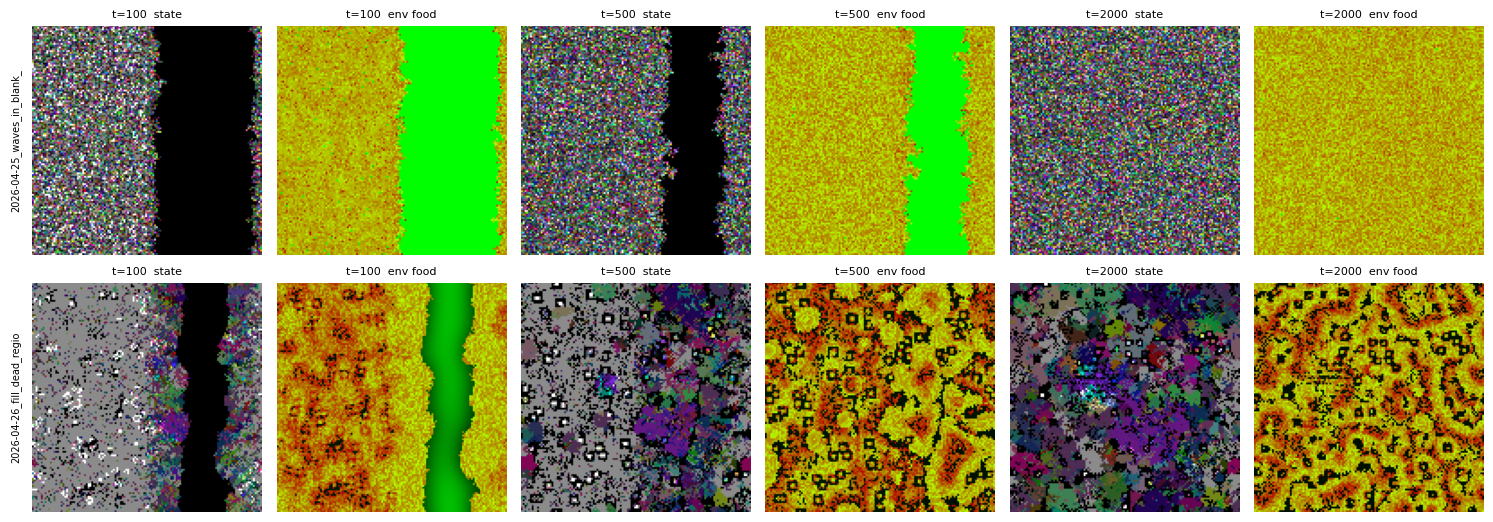

In [4]:
EXPL = [('2026-04-25_waves_in_blank_half.evoca', 'final'), ('2026-04-26_fill_dead_region_with_evolving_patches.evoca', 'init')]
fig, axs = plt.subplots(2, 6, figsize=(15, 5.4))
for i, (nm, rec) in enumerate(EXPL):
    shots, df = run_track(nm, N=128, snaps=(100, 500, 2000), n_steps=2000, recipe=rec)
    for j, t in enumerate((100, 500, 2000)):
        for k, cm in enumerate((0, 1)):
            ax = axs[i, 2*j+k]; ax.imshow(shots[t][cm]); ax.axis('off')
            ax.set_title(f"t={t}  {'state' if cm==0 else 'env food'}", fontsize=8)
    axs[i, 0].text(-0.05, 0.5, nm[:26], transform=axs[i,0].transAxes, rotation=90, ha='right', va='center', fontsize=7)
    print(nm[:50], 'alive@t=2000: %.3f' % df.alive_density.iloc[-1], 'corr_len mean %.1f' % df.correlation_length.mean())
plt.tight_layout(); plt.show()

In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim, kw = import_run('2026-04-25_waves_in_blank_half.evoca', N=256, recipe='final')
# # or: import_run('2026-04-26_fill_dead_region_with_evolving_patches.evoca', N=256, recipe='init')
# run_with_controls(sim, cell_px=2, **kw)

**Observations (example runs, N=128, not campaign results).** With its saved final parameters the `waves` recipe is a **front invasion**: a living front advances into the blank half and the lattice fills (alive density > 0.99 by t~1250 at N=128; the front is still crossing at N=256 by t=2000, 0.95). It is a traveling front, not a sustained oscillating wave. The `fill_dead_region` recipe (gdiff=20, i.e. food is nearly homogenized every step) shows grey frozen blocks/domains with sharp boundaries in the state view and a patchwork of food-depleted seams: a **domain mosaic** regime. These two hand-found recipes motivated the systematic 04-27 search below. The `gdiff` value 20 is outside every scan grid (max 0.20), so the mosaic regime has never been scanned (see RXD-Q4 in ISSUES).

## 2026-04-27: the three RD scans (initial, refined, push_edges)

**Question.** Is there a pocket of (food_inc, tax, gdiff, m_scale, mu_lut, mu_egenome, restricted_mu) where large-scale spatial structure and ongoing genomic turnover coexist? **What was done.** Random samples of 150/200/250 configs from progressively tightened grids, N=256, 5000 steps, halfplane start, seed 0, shadow on ([notes](Scans/2026-04-27_scan_analysis.md)). Ranked by an unweighted mean of four min-max-normalized metrics (`correlation_length_mean`, `largest_patch_temporal_std`, `n_distinct_genomes_temporal_std`, `unique_top_genomes`).

Recorded results reproduced from `results.csv`:

,n,extinct,candidates,yield,max_corr_len,max_patch_std
scan,,,,,,
initial,150,31,25,0.17,50.6,8478.0
refined,200,101,99,0.50,82.7,15825.0
push_edges,250,5,245,0.98,75.8,17277.0


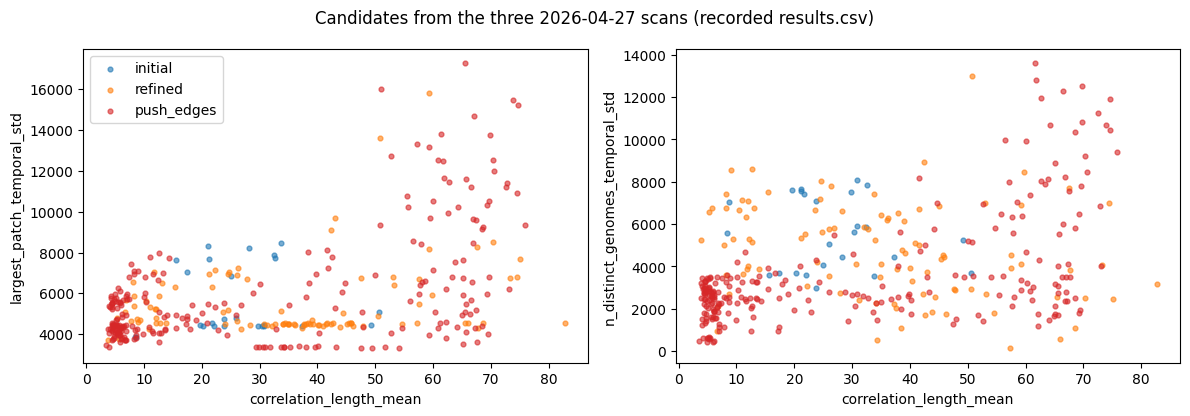

In [5]:
frames = {}
for s in ('initial', 'refined', 'push_edges'):
    d = pd.read_csv(SCANS / f'2026-04-27_{s}' / 'results.csv'); d['scan'] = s; frames[s] = d
allr = pd.concat(frames.values(), ignore_index=True)
allr['candidate'] = (~allr.extinct.astype(bool)) & (allr.alive_density_mean <= 0.95)
summ = allr.groupby('scan', sort=False).agg(n=('config_idx', 'size'), extinct=('extinct', 'sum'),
        candidates=('candidate', 'sum'))
summ['yield'] = (summ.candidates / summ.n).round(2)
cand = allr[allr.candidate]
summ['max_corr_len'] = cand.groupby('scan').correlation_length_mean.max().round(1)
summ['max_patch_std'] = cand.groupby('scan').largest_patch_temporal_std.max().round(0)
display(summ)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for s, c in zip(('initial', 'refined', 'push_edges'), ('C0', 'C1', 'C3')):
    d = cand[cand.scan == s]
    ax[0].scatter(d.correlation_length_mean, d.largest_patch_temporal_std, s=12, alpha=.6, c=c, label=s)
    ax[1].scatter(d.correlation_length_mean, d.n_distinct_genomes_temporal_std, s=12, alpha=.6, c=c, label=s)
ax[0].set(xlabel='correlation_length_mean', ylabel='largest_patch_temporal_std'); ax[1].set(xlabel='correlation_length_mean', ylabel='n_distinct_genomes_temporal_std')
ax[0].legend(); plt.suptitle('Candidates from the three 2026-04-27 scans (recorded results.csv)'); plt.tight_layout(); plt.show()

Minor discrepancy noted: `results.csv` `extinct` counts 101 rows in `refined` and 5 in `push_edges`, whereas the analysis doc splits non-candidates into extinct/saturated as ~25/~76 and ~3/~2; the candidate counts (99, 245) agree. The doc's split looks approximate.

**Recorded findings** (from the cross-scan analysis): candidate yield rose from 17% (initial) to 50% (refined) to 98% (push_edges); correlation length plateaus near 75-80 cells, about N/3, and was flagged as possibly grid-size bound; `gdiff` bracketed near 0.06, `food_inc` near 0.013, `m_scale` still unbracketed at the grid edge. The analysis doc also states that optimizing for evolution did not sacrifice spatial structure ("no Pareto trade-off in the regime we're searching"). That claim rested on ranks within the best-scoring corner; the scatter on the right (genome turnover vs. correlation length) is the place to test it, see the two-objective section below.

**Directions that came out of it:** N=384/512 scan for the plateau; bracket `m_scale` and `mu_lut`; multi-seed re-runs of winners (the latter became campaign #4).

## The gallery: six-plus visual regimes

**What was done.** From the 55 distinct configs behind the 85 recipes in `Runs/` (many recipes are the same config under different rankings: `top_N`, `top_evo_N`, `auto_*`, `best_corr_length`), nine recipes were chosen from the scans' `correlation_length_mean`, `largest_patch_temporal_std` and `n_patches_mean` to span visibly different regimes. Each is run at N=128 for 2000 steps (seed 0). Rows are the lattice at t=150, 600 and 2000 in colormode 0 (state; white/grey/colors = genome-hash colors of alive cells), 1 (env food; bright green = unexploited food, orange/red = depleted) and 3 (births). Regime names are descriptive labels given here, not recorded classifications.

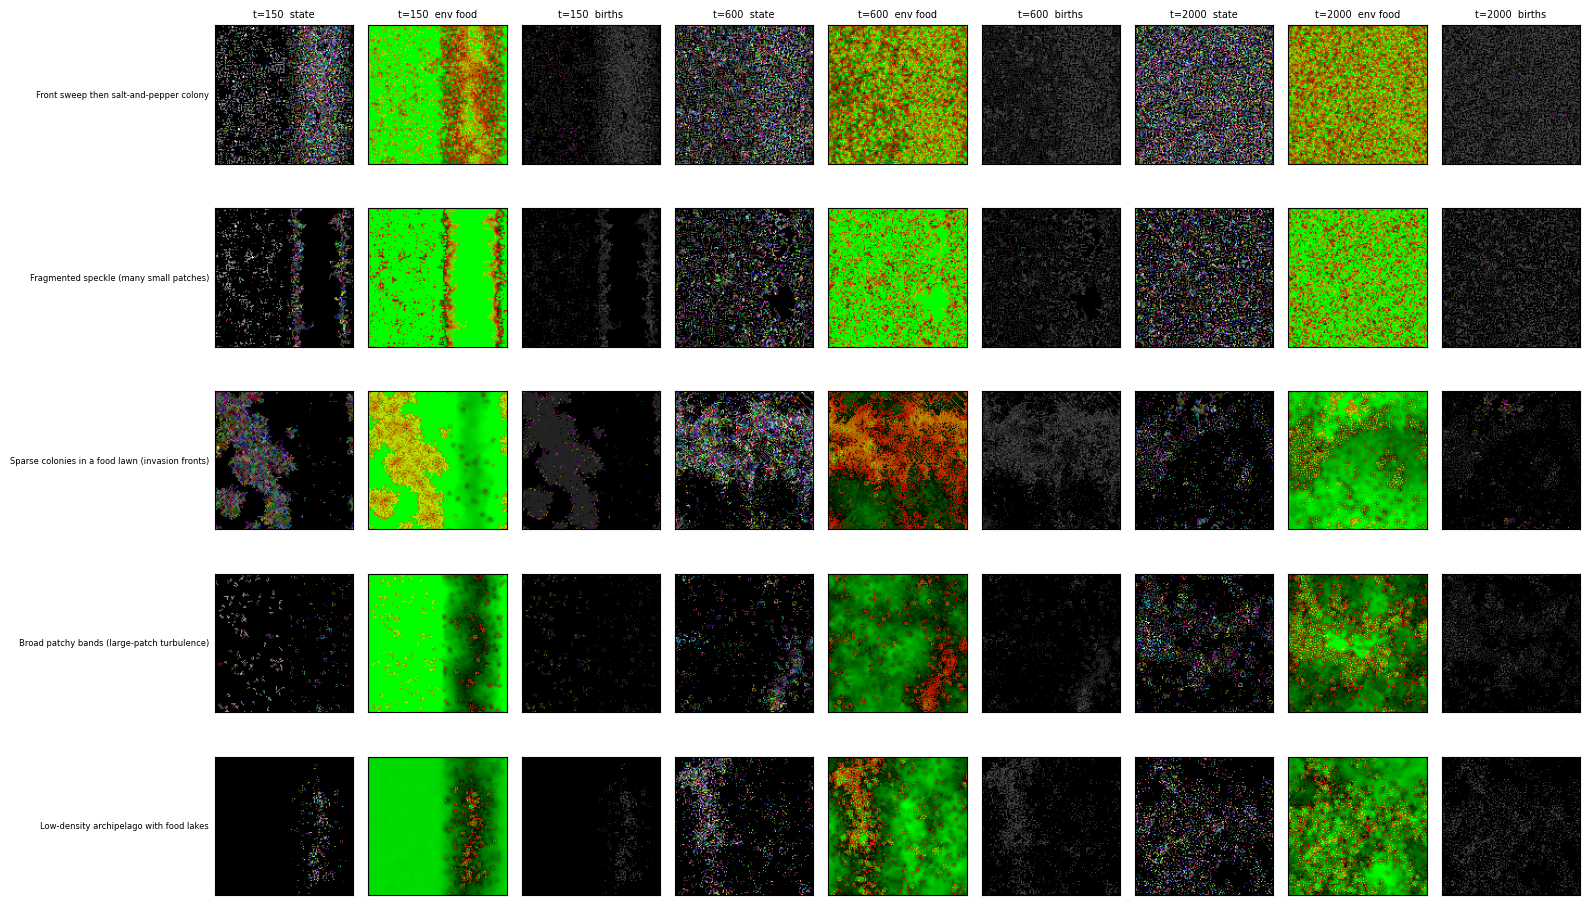

In [6]:
GALLERY = [
  # (recipe, recipe-params, regime name)
  ('2026-04-27_top_1_cfg49_score0.75.evoca',  'init', 'Front sweep then salt-and-pepper colony'),
  ('2026-04-27_top_10_cfg39_score0.55.evoca', 'init', 'Fragmented speckle (many small patches)'),
  ('2026-04-27_top_1_cfg236_score0.90.evoca', 'init', 'Sparse colonies in a food lawn (invasion fronts)'),
  ('2026-04-27_top_16_cfg102_score0.73.evoca','init', 'Broad patchy bands (large-patch turbulence)'),
  ('2026-04-27_top_4_cfg247_score0.82.evoca', 'init', 'Low-density archipelago with food lakes'),
  ('2026-04-27_top_evo_19_cfg53_score0.52.evoca','init','Labyrinth texture (high gdiff, short correlation)'),
  ('2026-04-26_fill_dead_region_with_evolving_patches.evoca','init','Frozen domain mosaic (gdiff=20)'),
  ('2026-04-27_R-D_to_static_colony_filling_world.evoca','init','Uniform dot lattice (RD-to-static end state)'),
  ('2026-04-25_waves_in_blank_half.evoca', 'final', 'Invasion front into blank half'),
]
SNAPS = (150, 600, 2000)
gal, gal_ts = {}, {}
for nm, rec, reg in GALLERY:
    gal[nm], gal_ts[nm] = run_track(nm, N=128, snaps=SNAPS, n_steps=2000, recipe=rec)
CMN = {0: 'state', 1: 'env food', 3: 'births'}
def draw(rows, fname):
    fig, axs = plt.subplots(len(rows), 9, figsize=(16, 1.9*len(rows)))
    for i, (nm, rec, reg) in enumerate(rows):
        for j, t in enumerate(SNAPS):
            for k, cm in enumerate((0, 1, 3)):
                ax = axs[i, 3*j+k]; ax.imshow(gal[nm][t][cm]); ax.set_xticks([]); ax.set_yticks([])
                if i == 0: ax.set_title(f't={t}  {CMN[cm]}', fontsize=7)
        axs[i, 0].set_ylabel(reg, fontsize=6, rotation=0, ha='right', va='center', labelpad=4)
    plt.tight_layout(); plt.show()
draw(GALLERY[:5], 'a')

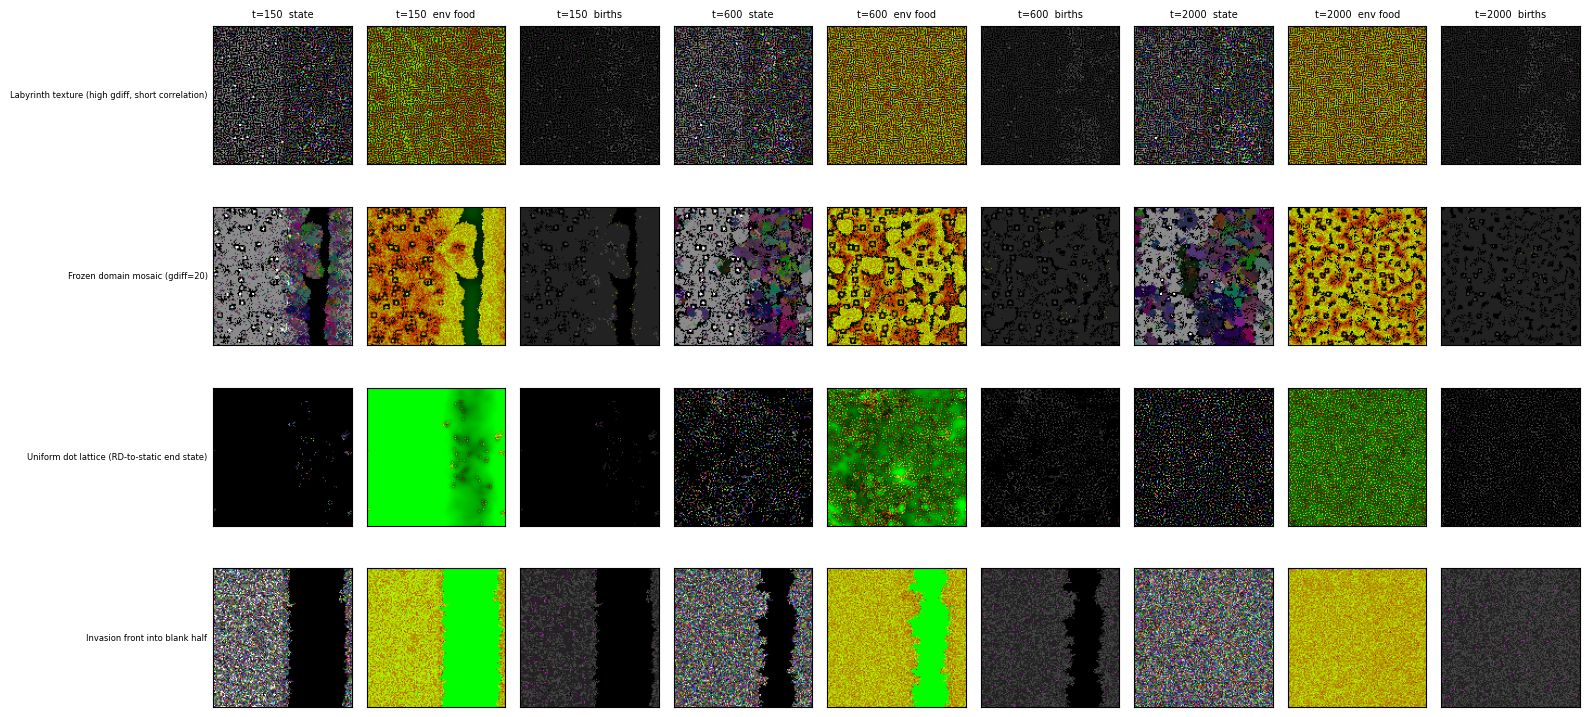

In [7]:
draw(GALLERY[5:], 'b')

In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# name, rec, regime = GALLERY[2]   # any gallery entry, 0-8 (see the list above)
# sim, kw = import_run(name, N=256, recipe=rec)
# run_with_controls(sim, cell_px=2, **kw)

### Regime table: recipe, regime, key metrics

"scan" columns are the recorded `results.csv` row (N=256, 5000 steps); "ex" columns are measured in this notebook (N=128, 2000 steps, sampled every 25 steps, seed 0; not campaign results). Recipes without a scan row (hand-found) show dashes.

In [8]:
cache = {}
def scan_row(nm):
    d = json.load(open(RUNS / nm)); s = d.get('source_scan')
    if not s: return None
    key = s.replace('Research/', '')
    if key not in cache: cache[key] = pd.read_csv(ROOT / 'Research' / key / 'results.csv').set_index('config_idx')
    return cache[key].loc[d['source_config_idx']]
rows = []
for nm, rec, reg in GALLERY:
    s = scan_row(nm); e = summarize(gal_ts[nm], t_start=0)
    rows.append({'recipe': nm.replace('.evoca','').replace('2026-04-','')[:44], 'regime': reg,
        'scan corr_len': None if s is None else round(s.correlation_length_mean,1),
        'scan patch_std': None if s is None else round(s.largest_patch_temporal_std),
        'scan n_patches': None if s is None else round(s.n_patches_mean),
        'scan alive': None if s is None else round(s.alive_density_mean,2),
        'ex corr_len': round(e['corr_len_mean'],1), 'ex patch_std': round(e['patch_std']),
        'ex n_patches': round(e['n_patches_mean']), 'ex alive': round(e['alive_mean'],2)})
reg_tab = pd.DataFrame(rows); display(reg_tab.fillna('-'))

,recipe,regime,scan corr_len,scan patch_std,scan n_patches,scan alive,ex corr_len,ex patch_std,ex n_patches,ex alive
0,27_top_1_cfg49_score0.75,Front sweep then salt-and-pepper colony,21.1,8314.0,455.0,0.7,12.4,1814,101,0.70
1,27_top_10_cfg39_score0.55,Fragmented speckle (many small patches),19.7,4436.0,4006.0,0.45,15.9,1780,1135,0.41
2,27_top_1_cfg236_score0.90,Sparse colonies in a food lawn (invasion fronts),73.9,15484.0,1804.0,0.32,39.9,3690,652,0.34
3,27_top_16_cfg102_score0.73,Broad patchy bands (large-patch turbulence),65.5,17277.0,1744.0,0.39,39.4,4697,587,0.40
4,27_top_4_cfg247_score0.82,Low-density archipelago with food lakes,61.7,12466.0,476.0,0.22,40.8,1471,960,0.25
5,27_top_evo_19_cfg53_score0.52,"Labyrinth texture (high gdiff, short correlation)",4.5,4440.0,404.0,0.6,2.1,2021,180,0.61
6,26_fill_dead_region_with_evolving_patches,Frozen domain mosaic (gdiff=20),-,-,-,-,8.0,869,97,0.78
7,27_R-D_to_static_colony_filling_world,Uniform dot lattice (RD-to-static end state),-,-,-,-,11.2,1428,2023,0.25
8,25_waves_in_blank_half,Invasion front into blank half,-,-,-,-,28.2,3186,15,0.87


**Observations (example runs, N=128).**

- *Front sweep then salt-and-pepper colony* (cfg49, also cfg30; `best_corr_length`): the left-half colony sweeps across, then the lattice fills with a fine speckle whose correlation length collapses to ~2 cells. The scan's corr_len 21 is dominated by the first few hundred steps of the sweep (the transient front is the "structure"); at N=128 the front crosses the grid even faster. This is the configuration family behind campaign #4's "static colony-filling blob".
- *Fragmented speckle* (cfg39, cfg82): same fate with more, smaller patches (n_patches ~4000 at N=256).
- *Sparse colonies in a food lawn* (cfg236, the balanced-composite #1): the lowest alive density of the set at t=150-600, small colonies in an almost untouched food field, colonies expand into a large food-depleted region by t=600, then retreat, leaving sparse live cells in a recovering food field at t=2000; the most front-like of the scan winners.
- *Broad patchy bands* (cfg102, largest `largest_patch_temporal_std` of the scans): large patches grow and shrink over the whole run; food-depleted orange/red bands persist across the lattice at t=2000.
- *Low-density archipelago* (cfg247): alive fraction 0.2-0.4 with food lakes, the regime that still shows structure at t=2000.
- *Labyrinth texture* (cfg53, gdiff=0.2): the one recipe from scan edges where diffusion is high; uniform maze-like stripes, correlation length ~1-4, n_top_genomes=1. Visually striking but spatially featureless at the correlation-length metric: shows the metric measures *scale*, not pattern order.
- *Frozen domain mosaic* and *uniform dot lattice*: hand-found end states (gdiff 20; and the 04-27 recipe named "R-D to static colony filling world"). The latter at N=128 passes through a structured band at t=600 and ends as a regular dot lattice by t=2000, which is exactly its saved name.

No spirals were observed in these nine runs; "spiral" is not a regime claimed here.

### N=256 showcase

One frame at the scan's own grid size: the balanced-composite #1 (cfg236) at t=1500, colormodes 0 / 1 / 3.

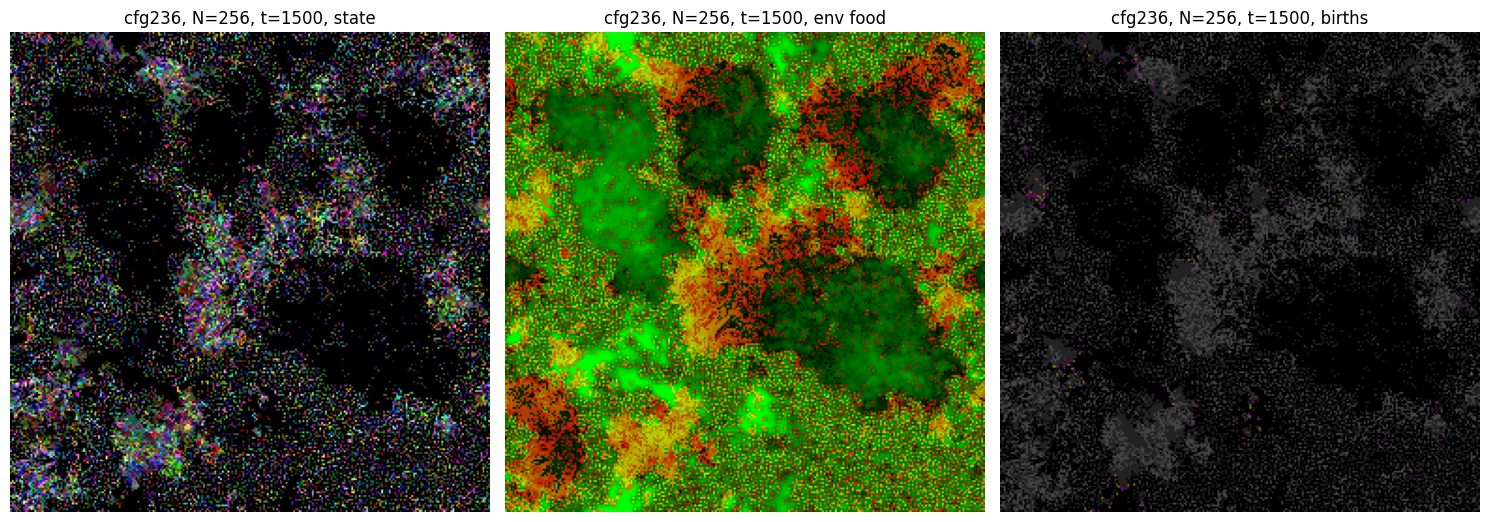

N=256 example: corr_len mean 69.0, alive final 0.37 (scan row, 5000 steps: corr_len 73.9, alive mean 0.32)


In [9]:
shots, df256 = run_track('2026-04-27_top_1_cfg236_score0.90.evoca', N=256, snaps=(1500,), n_steps=1500, every=100)
fig, axs = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, cm in zip(axs, (0, 1, 3)):
    ax.imshow(shots[1500][cm]); ax.set_title(f'cfg236, N=256, t=1500, {CMN[cm]}'); ax.axis('off')
plt.tight_layout(); plt.show()
print('N=256 example: corr_len mean %.1f, alive final %.2f (scan row, 5000 steps: corr_len 73.9, alive mean 0.32)' % (df256.correlation_length.mean(), df256.alive_density.iloc[-1]))

In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim, kw = import_run('2026-04-27_top_1_cfg236_score0.90.evoca', N=256)
# run_with_controls(sim, cell_px=2, **kw)

## 2026-05-18: campaign #4, RD under pure evolution

**Question.** Does the RD structure that the 2026-04-27 *spatial* objective selected persist when the winner is simply run long? **What was done.** 10 distinct 04-27 winner recipes x 3 seeds, 12000 steps, N=256 ([notes](Scans/2026-05-18_rd_under_pure_evo/notes.md), digest [RD-robustness](digests/RD-robustness.ipynb)). Diagnostic: `correlation_length_final / correlation_length_mean`.

A note on what "pure-evo parameters" means here: the scan reuses each winner's metaparameters unchanged (`scan.py::load_bases`); what changes is the horizon (12000 vs 5000 ticks) and the evo-based reading of the outcome. There is no second parameter set, so the "original vs pure-evo" comparison below is the same recipe observed over its original 5000-tick scoring window versus the long horizon. (The scan's base list is the ten distinct `top_N_cfg*_score0.5-0.75` recipes, all from the `initial` scan, not the higher-scoring push_edges winners; this is a limit of the campaign, see RXD-Q2.)

**Recorded results** (the committed `results.csv`):

runs 30 | extinct 0 | corr_len final/mean median 0.23, max 0.89


,cl_mean,cl_final,cl_fm,lp_fm,alive_mean,dyn_excess_slope
top_10_cfg39_score0.55,15.57,1.00,0.06,0.33,0.44,16.91
top_4_cfg34_score0.63,8.05,1.00,0.13,0.44,0.42,21.26
top_9_cfg82_score0.55,6.54,1.00,0.15,0.27,0.41,26.47
top_2_cfg30_score0.72,5.25,1.00,0.19,1.01,0.70,5.78
top_1_cfg49_score0.75,4.70,1.00,0.23,1.00,0.70,5.71
top_7_cfg87_score0.60,19.56,6.00,0.30,0.19,0.42,22.69
top_8_cfg111_score0.58,15.73,8.67,0.54,0.57,0.46,12.91
top_6_cfg3_score0.61,18.15,11.33,0.60,0.53,0.53,13.26
top_3_cfg70_score0.68,16.67,10.67,0.61,0.30,0.50,12.80
top_5_cfg35_score0.62,15.38,9.67,0.69,0.46,0.45,13.93


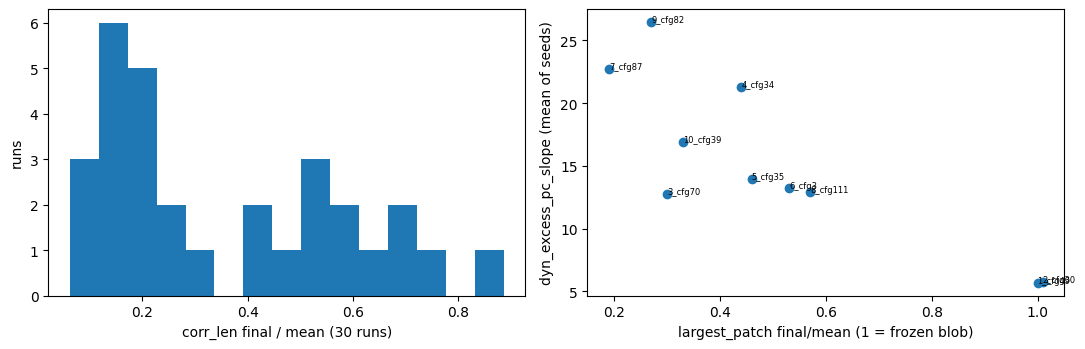

In [10]:
pe = pd.read_csv(SCANS / '2026-05-18_rd_under_pure_evo' / 'results.csv')
print('runs', len(pe), '| extinct', int(pe.extinct.sum()), '| corr_len final/mean median %.2f, max %.2f' % (
      pe.correlation_length_final_over_mean.median(), pe.correlation_length_final_over_mean.max()))
per = pe.groupby('base').agg(cl_mean=('correlation_length_mean','mean'), cl_final=('correlation_length_final','mean'),
        cl_fm=('correlation_length_final_over_mean','median'), lp_fm=('largest_patch_final_over_mean','median'),
        alive_mean=('alive_density_mean','mean'), dyn_excess_slope=('dyn_excess_pc_slope','mean')).round(2)
per.index = [i.replace('2026-04-27_','').replace('.evoca','') for i in per.index]
display(per.sort_values('cl_fm'))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(pe.correlation_length_final_over_mean, bins=15); ax[0].set(xlabel='corr_len final / mean (30 runs)', ylabel='runs')
ax[1].scatter(per.lp_fm, per.dyn_excess_slope); ax[1].set(xlabel='largest_patch final/mean (1 = frozen blob)', ylabel='dyn_excess_pc_slope (mean of seeds)')
for n, r in per.iterrows(): ax[1].annotate(n.split('_score')[0][4:], (r.lp_fm, r.dyn_excess_slope), fontsize=6)
plt.tight_layout(); plt.show()

**Example run: illustrating the decay.** Three of the campaign's recipes re-run at N=128 for 12000 steps (seed 0), correlation length of the alive mask every 100 steps; the grey band is the original 5000-tick scoring window. These are single N=128 runs; the recorded N=256, 3-seed ratios are printed in the legend for comparison. Colormode 0 snapshots at t=1000 and t=12000 are underneath.

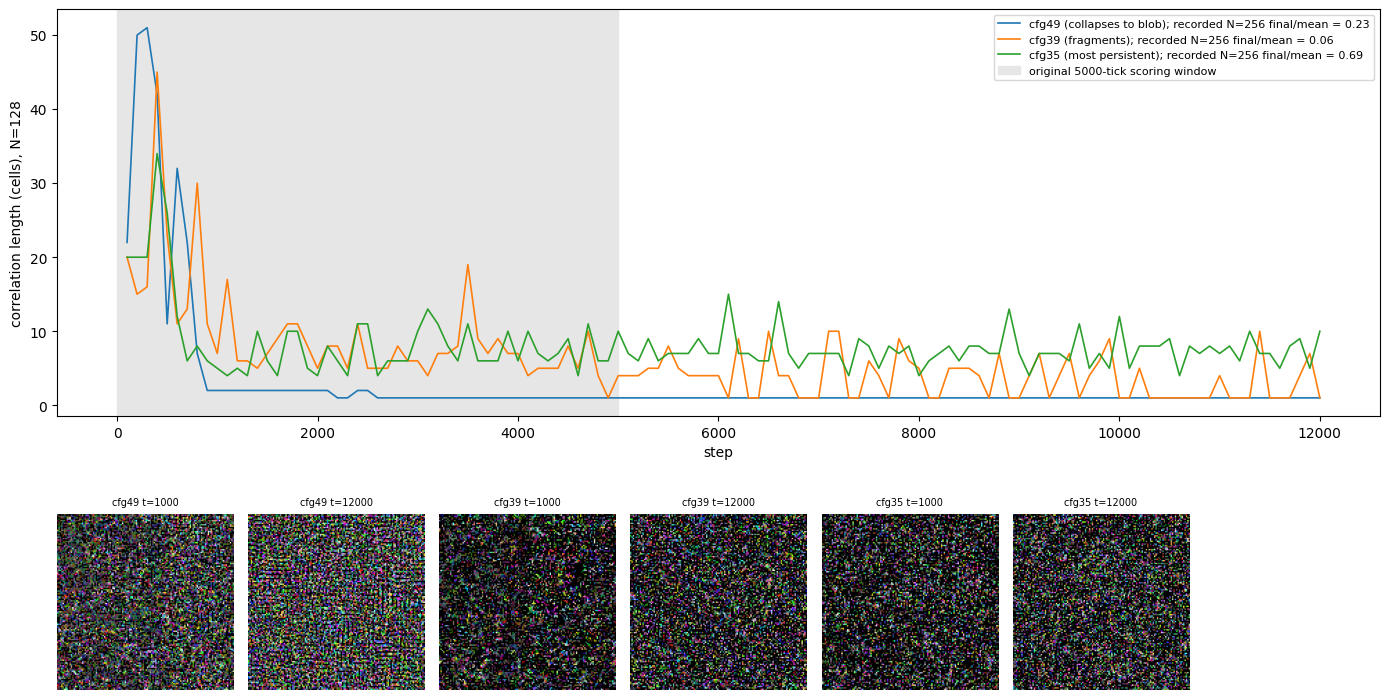

2026-04-27_top_1_cfg49_score0. corr_len mean over first 5000: 5.9 | over 5000-12000: 1.0 | final: 1.0 | alive final 0.70
2026-04-27_top_10_cfg39_score0 corr_len mean over first 5000: 9.6 | over 5000-12000: 3.6 | final: 1.0 | alive final 0.46
2026-04-27_top_5_cfg35_score0. corr_len mean over first 5000: 9.0 | over 5000-12000: 7.4 | final: 10.0 | alive final 0.48


In [11]:
DEC = [('2026-04-27_top_1_cfg49_score0.75.evoca', 'cfg49 (collapses to blob)'),
       ('2026-04-27_top_10_cfg39_score0.55.evoca', 'cfg39 (fragments)'),
       ('2026-04-27_top_5_cfg35_score0.62.evoca', 'cfg35 (most persistent)')]
fig = plt.figure(figsize=(14, 7.5)); gs = fig.add_gridspec(2, 7, height_ratios=[1.6, 1])
axl = fig.add_subplot(gs[0, :]); res = {}
for i, (nm, lab) in enumerate(DEC):
    shots, df = run_track(nm, N=128, snaps=(1000, 12000), n_steps=12000, every=100, cms=(0,))
    res[nm] = (shots, df)
    rec = per.loc[nm.replace('2026-04-27_','').replace('.evoca','')]
    axl.plot(df.index, df.correlation_length, label=f"{lab}; recorded N=256 final/mean = {rec.cl_fm:.2f}", lw=1.2)
    for j, t in enumerate((1000, 12000)):
        ax = fig.add_subplot(gs[1, 2*i + j + (1 if i else 0)] if False else gs[1, [0,1,2,3,4,5][2*i+j]]); ax.imshow(shots[t][0]); ax.axis('off'); ax.set_title(f'{lab.split()[0]} t={t}', fontsize=7)
axl.axvspan(0, 5000, color='0.9', label='original 5000-tick scoring window'); axl.set(xlabel='step', ylabel='correlation length (cells), N=128'); axl.legend(fontsize=8)
plt.tight_layout(); plt.show()
for nm, (s, df) in res.items():
    w = df[df.index <= 5000]; print(nm[:30], 'corr_len mean over first 5000: %.1f | over 5000-12000: %.1f | final: %.1f | alive final %.2f' % (
        w.correlation_length.mean(), df[df.index > 5000].correlation_length.mean(), df.correlation_length.iloc[-1], df.alive_density.iloc[-1]))

In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# (the decay takes thousands of steps; the window runs indefinitely)
# from controls import run_with_controls
# sim, kw = import_run('2026-04-27_top_5_cfg35_score0.62.evoca', N=256)   # or cfg49 / cfg39 (see DEC above)
# run_with_controls(sim, cell_px=2, **kw)

**Observations (example runs, N=128, not campaign results).** In all three runs the large correlation lengths (up to ~50) occur only in the first ~600 steps, while the halfplane front crosses the grid; afterwards cfg35 and cfg39 sit at ~5-8 cells and cfg49 drops to 1 (a fully filled, speckled lattice: the static blob). The recorded N=256 ratios (cfg39 0.06 lowest, cfg35 0.69 highest) are only loosely reproduced: at N=128 cfg39 is not clearly worse than cfg35 after the transient. The timescale is also shorter because the grid is smaller; N=128 cannot adjudicate the size of the effect. A caveat worth stating: the halfplane start makes the first ~N steps an invasion front by construction, so "mean over the run" credits the transient; a mean taken after a burn-in would separate structure the dynamics maintain from structure the initial condition imposes (RXD-N2).

**Directions that came out of it:** re-rank on the long-horizon quantity; test whether any config keeps final/mean near 1 *and* high turnover (none of the 10 bases, in the recorded data, combine them); re-select with a genuine two-objective method.

## Two objectives: a preview of cone/box re-selection

**Why.** Spatial structure and evolutionary activity are the only truly two-objective pair in the program. The past selection was a scalar unweighted mean of four normalized metrics (`Docs/Oct2026/00-review-of-prompt1.md` §6), which lets a lopsided config with one extreme metric outrank a balanced one. The `conepareto` package (`~/Projects/conepareto`, `Docs/Oct2026/05-cone-pareto-package.md`) offers a box (floors on both) and a wedge (bounded imbalance) over Pareto layers.

**Preview experiment (cheap; recorded data only, no new simulations).** Pool the candidates of the three 04-27 scans; spatial score = mean of normalized `correlation_length_mean` and `largest_patch_temporal_std`; evolution score = mean of normalized `n_distinct_genomes_temporal_std` and `unique_top_genomes`. Compare the top-20 by (a) the pooled composite mean, (b) a box with floors, (c) a wedge. This is a preview of the proposed first experiment (RXD-N1), not a result: score choices, pool normalization (pooled here, per-scan in the original) and `unique_top_genomes` saturation at the sample cap are all open.

pool 369 | Pareto layers 57 | front size 3
box relaxed False floors (0.63, 0.52) worst_imbalance 0.36 layers [1, 2, 3, 4, 5]
wedge relaxed False floors (0.61, 0.51) worst_imbalance 0.15 layers [1, 2, 3, 4, 5, 6, 7, 8]
overlap with composite top-20: {'box 0.5/0.5': 18, 'wedge (imb<=0.15)': 12} | box&wedge 12


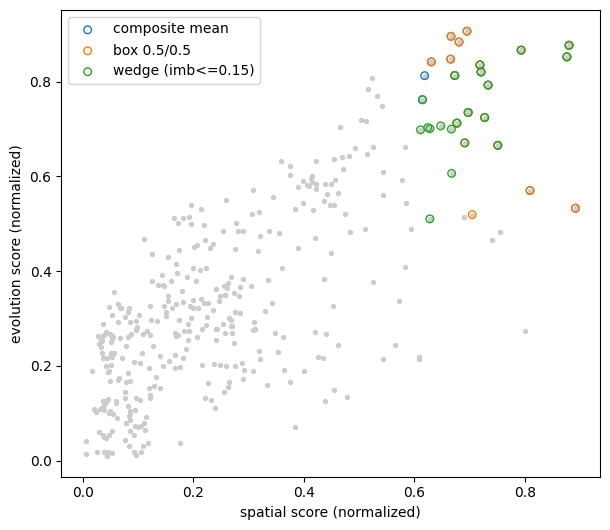

In [12]:
try:
    sys.path.insert(0, str(Path.home() / 'Projects' / 'conepareto' / 'src'))
    import conepareto as cp; HAVE_CP = True
except Exception as ex:
    HAVE_CP = False; print('conepareto not importable:', ex)
if HAVE_CP:
    c = cand.reset_index(drop=True)
    nv = lambda x: cp.normalize_values(np.asarray(x, float))
    s_sp = (nv(c.correlation_length_mean) + nv(c.largest_patch_temporal_std)) / 2
    s_ev = (nv(c.n_distinct_genomes_temporal_std) + nv(c.unique_top_genomes)) / 2
    K = 20
    comp = np.argsort(-((s_sp + s_ev) / 2).values if hasattr(s_sp,'values') else -((s_sp + s_ev) / 2))[:K]
    layers = cp.pareto_layers(s_sp, s_ev)
    box = cp.select(s_sp, s_ev, 'box', K, layer_index=layers, first_exclude_fraction=0.5, second_exclude_fraction=0.5)
    wdg = cp.select(s_sp, s_ev, 'wedge', K, layer_index=layers, max_imbalance=0.15)
    sets = {'composite mean': set(comp), 'box 0.5/0.5': set(box.indices), 'wedge (imb<=0.15)': set(wdg.indices)}
    print('pool', len(c), '| Pareto layers', layers.max(), '| front size', int((layers == 1).sum()))
    for nme, sel in (('box', box), ('wedge', wdg)):
        r = sel.report; print(nme, 'relaxed', r.relaxed, 'floors', tuple(round(x,2) for x in r.floors_achieved), 'worst_imbalance %.2f' % r.worst_imbalance, 'layers', r.layers_used)
    names = list(sets)
    print('overlap with composite top-%d:' % K, {n: len(sets[n] & sets['composite mean']) for n in names[1:]}, '| box&wedge', len(sets['box 0.5/0.5'] & sets['wedge (imb<=0.15)']))
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    ax.scatter(s_sp, s_ev, s=8, c='0.8')
    for (nme, st), col in zip(sets.items(), ('C0', 'C1', 'C2')):
        ii = np.array(sorted(st)); ax.scatter(s_sp.iloc[ii] if hasattr(s_sp,'iloc') else s_sp[ii], s_ev.iloc[ii] if hasattr(s_ev,'iloc') else s_ev[ii], s=30, facecolors='none', edgecolors=col, label=nme)
    ax.set(xlabel='spatial score (normalized)', ylabel='evolution score (normalized)'); ax.legend(); plt.tight_layout(); plt.show()

**Reading it (this execution).** Pool of 369 candidates, 57 Pareto layers, only 3 on the front. The box (0.5/0.5 exclusion floors) shares 18 of 20 picks with the composite top-20 (worst imbalance 0.36); the wedge (max imbalance 0.15) shares 12 of 20, and 12 with the box. So the composite already behaves close to a box here, and the wedge is the method that changes the answer. The point is not which set is "right" but that the three methods can disagree, and that the box makes the floor on each axis explicit. The proposed experiment (RXD-N1) hardens this: per-scan and pooled normalization, `n_distinct_genomes_temporal_std` plus an excess/A_new axis for evolution once the merged metrics are available, then run the three top-20 sets at N=256 with the 12000-step long horizon and score each by *persistence* (final/mean) as the held-out criterion. Selection method wins if its picks keep structure under the long horizon.

## Current state and directions (2026-10)

- **Where things stand.** RD regimes are real and varied (front invasions, sparse colonies in a food lawn, broad patchy bands, archipelagos, labyrinth texture, frozen domain mosaics, uniform dot lattices; no spirals observed), but the spatial scale the 04-27 scans optimized is largely the invasion transient of a halfplane start, and under 12000-tick runs it is not a robust attractor (recorded #4: median final/mean 0.23, 2/10 static blobs). 85 recipes cover about 55 distinct configs.
- **Newly unblocked by the 2026-10-15 merges.** `dyn_activity` and A_new / eff_activity / z-scores now exist as evolution axes; lineage net-return (D2) and dissipation Phi (L1) are candidate second objectives; the conepareto package provides the selection machinery. See ISSUES.md.
- **Outstanding decisions and items:** see RXD-D1 (what counts as the second objective), RXD-D2 (halfplane vs. fraction init as the RD protocol) and RXD-N1 (the box/wedge re-selection experiment), RXD-N2 (burn-in/persistence-based spatial metrics) in ISSUES.md above.

In [13]:
print('notebook wall time: %.0f s' % (time.time() - _t0))

notebook wall time: 44 s
